this file is to develop the executable python script

# imports

In [1]:
import pandas as pd
import os
import numpy as np
from collections import defaultdict
import matplotlib.pyplot as plt
import sys
sys.path.append("/home/dekorvyb/Documents/criticality_pipeline/")
import tools
import seaborn as sns

INFO     Loaded mrestimator v0.1.8, writing to /tmp/mre_dekorvyb/
INFO     Numba not available, skipping parallelization
INFO     No display found. Using non-interactive Agg backend for plotting. Check your $DISPLAY environment variable.


In [ ]:
# variables
bin_size = 5 # in miliseconds. So now we bin activity to bin seconds
result_dir = '/groups/cns/share/Vincent/McHugh_lab/CA2Cre_DREADD/Results_March_26'
results_dir = '/groups/cns/share/Vincent/McHugh_lab/CA2Cre_DREADD/Results_March_26_Control'


# criticality algorithm

In [2]:
# here are the extracted spike trains, one for each day-session-area combination
spike_directory = '/groups/cns/share/Vincent/McHugh_lab/CA2Cre_DREADD/extracted_spike_trains/'

# animal-day-combinations where there's CNO and at least one pre- and post-session
good_combinations = ["model144_d16",
                    "model161_d10",
                    "model161_d12",
                    "model248_d11",
                    "model368_d14",
                    "model368_d16",
                    "model550_d16",
                    "model550_d17",
                    "model550_d21",
                    "model556_d12",
                    "model556_d13",
                    "model556_d19",
                    "model572_d16",
                    "model572_d17",
                    "model572_d18",
                    "model1216_d10",
                    "model1216_d12",
                    "model1223_d12",
                    "model1223_d13",
                    "model1223_d14",
                    "model1223_d15",
                    "model1232_d13",
                    "model1232_d14",
                    "model1232_d15",
                    # "model248_d04" # not really useable, since it's: sleep - cno_2 - lt1
                    ]

    # get all filenames in spike_directory that match good_combinations

spike_filenames = []
for f in os.listdir(spike_directory):
    for combo in good_combinations:
        if f.startswith(combo):
            spike_filenames.append(f)
            break
spike_filenames.sort()

In [3]:
# example filename: 'model144_d10_cno2_tt7_CA2_post.npy'
# Initialize lists to store parsed data
animals = []
days = []
tasks = []
tetrodes = []
areas = []
treatments = []
filename_list = []
start_times = []
end_times = []
total_spikes = []
cno_injections = []
avg_activity_pre = []

# Parse each filename
for filename in spike_filenames:
    # Remove the '.npy'
    base = filename.split('.')[0]
    # Split by underscores
    parts = base.split('_')

    # Assign parts to variables
    animals.append(parts[0][5:]) # remove the 'model' from 'model144'
    days.append(parts[1][1:])  # Remove 'd' from 'd10'
    tasks.append(parts[2])
    tetrodes.append(parts[3][-1]) # get the '7' from tt7
    areas.append(parts[4])
    treatments.append(parts[5])
    filename_list.append(filename)
    
    # some will be populated later
    start_times.append(0) # first spike of a session
    end_times.append(0)
    total_spikes.append(0) # total spikes in a session. We'll then compute spiking density
    cno_injections.append(0)
    avg_activity_pre.append(0.0) # make sure that it's a float not an integer

# Create the DataFrame
df = pd.DataFrame({
    'Model': animals,
    'Day': days,
    'Session': tasks,
    'Tetrode': tetrodes,
    'Area': areas,
    'Treatment': treatments,
    'Start_time': start_times,
    'End_time': end_times,
    'Activity_total': total_spikes,
    'CNO_injection': cno_injections,
    'Avg_activity_pre': avg_activity_pre,
    'Filename': filename_list
})

# Display the DataFrame
# print(df)

In [4]:
print(df['Area'].unique())

df = df[~df['Area'].isin(['DEEP', 'CA2-CA1', 'CA3-CA2'])]
df['Area'] = df['Area'].replace({'CA3a': 'CA3', 'CA3b': 'CA3', 'CA3c': 'CA3', 'CA13b': 'CA3'})
print(df['Area'].unique())

['CA2' 'CA3a' 'CA3c' 'CA1' 'CA3b' 'CA13b' 'CA3' 'DEEP' 'CA2-CA1' 'CA3-CA2']
['CA2' 'CA3' 'CA1']


In [ ]:

analyzed_prior = os.listdir(result_dir)

#------------
count = 0
df = df[(df['Session'] == 'sleep1') | (df['Session'].str.startswith('cno'))]

for index, row in df.iterrows():
    spike_train = np.load(f'{spike_directory}/{row['Filename']}')
    filename = f'{df.loc[index, 'Model']}_{df.loc[index, 'Day']}_{df.loc[index, 'Session']}_{df.loc[index, 'Area']}_{df.loc[index, 'Tetrode']}'
    if any(s.startswith(filename) for s in analyzed_prior):
        count+=1
        if count % 10 == 0:
            print(count)
        continue
    
    binned_spike_train = tools.bin_timestamps(spike_train, unit='us')
    tools.mr_estimator_for_numpy(binned_spike_train, window_size=90, bin_size = 5, filename=f'{result_dir}/{filename}', fit_func="f_complex")
    


10
20
30
40
50
60
70
80
90
100
110
120
130
140
150
160
170


WARNING  You should provide an ndarray of shape(numtrials, datalength)
         Continuing with one trial, reshaping your input
INFO     coefficients() with 'trialseparated' method for 1 trials of length 18000.
INFO     Bootstrapping needs at least 2 trials, skipping the resampling
INFO     Given data is no CoefficientResult. Guessing format
INFO     Bounded fit to $|A| e^{-k/\tau} + B e^{-(k/\tau_{osc})^\gamma} \cos(2 \pi \nu k) + C e^{-(k/\tau_{gs})^2} + O$
INFO     Fitting with 22 different start values
INFO     Finished fitting the data to f_complex,
         mre = 0.99910, tau = 1114.49ms, ssres = 0.10426
WARNING  The amplitude of the exponential decay is smaller than corrections: A=0.080645 B=0.003608 C=0.093417
WARNING  You should provide an ndarray of shape(numtrials, datalength)
         Continuing with one trial, reshaping your input
INFO     coefficients() with 'trialseparated' method for 1 trials of length 18000.
INFO     Bootstrapping needs at least 2 trials, skipping the 

analysed and saved /groups/cns/share/Vincent/McHugh_lab/CA2Cre_DREADD/Results_March_26/368_14_cno2_CA1_6_000.parquet


INFO     Finished fitting the data to f_complex,
         mre = 0.99046, tau = 104.28ms, ssres = 0.11691
WARNING  The amplitude of the exponential decay is smaller than corrections: A=0.036142 B=0.004420 C=0.110498
WARNING  You should provide an ndarray of shape(numtrials, datalength)
         Continuing with one trial, reshaping your input
INFO     coefficients() with 'trialseparated' method for 1 trials of length 18000.
INFO     Bootstrapping needs at least 2 trials, skipping the resampling
INFO     Given data is no CoefficientResult. Guessing format
INFO     Bounded fit to $|A| e^{-k/\tau} + B e^{-(k/\tau_{osc})^\gamma} \cos(2 \pi \nu k) + C e^{-(k/\tau_{gs})^2} + O$
INFO     Fitting with 22 different start values


analysed and saved /groups/cns/share/Vincent/McHugh_lab/CA2Cre_DREADD/Results_March_26/368_14_cno2_CA1_6_001.parquet


...

analysed and saved /groups/cns/share/Vincent/McHugh_lab/CA2Cre_DREADD/Results_March_26/572_18_sleep1_CA2_8_023.parquet


INFO     Finished fitting the data to f_complex,
         mre = 0.99920, tau = 1243.73ms, ssres = 0.11839
WARNING  The amplitude of the exponential decay is smaller than corrections: A=0.007404 B=0.174988 C=0.110988
WARNING  You should provide an ndarray of shape(numtrials, datalength)
         Continuing with one trial, reshaping your input
INFO     coefficients() with 'trialseparated' method for 1 trials of length 18000.
INFO     Bootstrapping needs at least 2 trials, skipping the resampling
INFO     Given data is no CoefficientResult. Guessing format
INFO     Bounded fit to $|A| e^{-k/\tau} + B e^{-(k/\tau_{osc})^\gamma} \cos(2 \pi \nu k) + C e^{-(k/\tau_{gs})^2} + O$
INFO     Fitting with 22 different start values


analysed and saved /groups/cns/share/Vincent/McHugh_lab/CA2Cre_DREADD/Results_March_26/572_18_sleep1_CA2_8_024.parquet


INFO     Finished fitting the data to f_complex,
         mre = 0.98556, tau = 68.74ms, ssres = 0.11958
WARNING  The amplitude of the exponential decay is smaller than corrections: A=0.021269 B=0.005296 C=0.150870


analysed and saved /groups/cns/share/Vincent/McHugh_lab/CA2Cre_DREADD/Results_March_26/572_18_sleep1_CA2_8_025.parquet


368_14_cno2_CA1_5_014.parquet
--> need to repeat this model-day-session-area-tatrode combination, interrupted too early (after 14 timechunks instead of 30)

# create result_df

In [ ]:
result_files = os.listdir(result_dir)

#
animals = []
days = []
sessions = []
areas = []
tetrodes = []
timechunks = []
filenames = []
#
taus = []
branching_factors = []
activities = []


# Parse each filename
for filename in result_files:
    # Remove the '.npy'
    base = filename.split('.')[0]
    # Split by underscores
    parts = base.split('_')

    # Assign parts to variables
    animals.append(parts[0]) 
    days.append(parts[1]) 
    sessions.append(parts[2])
    areas.append(parts[3])
    tetrodes.append(parts[4]) 
    timechunks.append(parts[5])
    filenames.append(filename)
    
    file_df = pd.read_parquet(f'{result_dir}/{filename}')
    try:
        taus.append(file_df['tau'][0])
        
    except:
        file_df.rename(columns={file_df.columns[0]: 'tau'}, inplace=True)
        file_df.to_parquet(f'{result_dir}/{filename}', index=True)
        taus.append(file_df['tau'][0])
    
    branching_factors.append(file_df['branching_factor'][0])
    activities.append(file_df['activity'][0])
    


# Create the DataFrame
result_df = pd.DataFrame({
    'Model': animals,
    'Day': days,
    'Session': sessions,
    'Area': areas,
    'Tetrode': tetrodes,
    'Timechunk': timechunks,
    'Filename': filenames,
    'Tau': taus,
    'Branching_factor': branching_factors,
    'Activity': activities
})


result_df.to_parquet('/groups/cns/share/Vincent/McHugh_lab/CA2Cre_DREADD/result_df_march_26.parquet', index=True)

# result analysis

In [4]:
result_df = pd.read_parquet('/groups/cns/share/Vincent/McHugh_lab/CA2Cre_DREADD/result_df_march_26.parquet')
result_df = result_df[result_df['Tau'] <= 3000]

In [5]:
baseline_criticality_df = result_df[result_df['Session'] == 'sleep1']
baseline_criticality_df = baseline_criticality_df.groupby(['Model', 'Day', 'Area', 'Tetrode']).agg({
    'Tau': 'mean',
    'Branching_factor': 'mean'
    }).reset_index()

In [7]:
# --- STEP 1: DATA CLEANING (The "Safety" Step) ---
# Ensuring all matching keys are strings and stripped of hidden spaces
match_cols = ['Model', 'Day', 'Area', 'Tetrode', 'Timechunk']
for col in match_cols:
    if col in result_df.columns:
        result_df[col] = result_df[col].astype(str).str.strip()

print(f"Unique Areas found: {result_df['Area'].unique()}")
print("--- Cleaning Complete ---\n")

# --- STEP 2: BASELINE CRITICALITY (Sleep 1) ---
# Average Tau per Tetrode during Sleep 1
baseline_crit_df = result_df[result_df['Session'] == 'sleep1'].groupby(
    ['Model', 'Day', 'Area', 'Tetrode']).agg({
    'Tau': 'mean',
    'Branching_factor': 'mean'
    }).reset_index().rename(columns={'Tau': 'baseline_tau', 'Branching_factor': 'baseline_bf'})

print(f"Baseline Tau calculated for {len(baseline_crit_df)} unique tetrodes.")


# --- STEP 3: CA2 ACTIVITY BASELINES ---
# Filter for CA2 only
ca2_only = result_df[result_df['Area'] == 'CA2'].copy()

# A) Current CA2 Activity (CNO Sessions): Sum activity over tetrodes per Timechunk
ca2_act_post = ca2_only[ca2_only['Session'].str.startswith('cno')].groupby(
    ['Model', 'Day', 'Timechunk']
    ).agg({
    'Activity': 'sum'
    }).reset_index().rename(columns={'Activity': 'current_ca2_activity'})


# B) Baseline CA2 Activity (Sleep 1): 
# First, sum activity over tetrodes per timechunk in Sleep 1
ca2_act_pre_chunks = ca2_only[ca2_only['Session'] == 'sleep1'].groupby(
    ['Model', 'Day', 'Timechunk']).agg({
    'Activity': 'sum'
    }).reset_index()
    
# Second, average those timechunk-sums to get a single baseline value per Day
ca2_act_pre = ca2_act_pre_chunks.groupby(['Model', 'Day']).agg({
    'Activity': 'mean'
    }).reset_index().rename(
    columns={'Activity': 'baseline_ca2_activity'})

print(f"CA2 Baselines created. Post-chunks: {len(ca2_act_post)}, Pre-averages: {len(ca2_act_pre)}")



# --- STEP 4: MERGING & CALCULATION ---
# Start with the main CNO data
final_df = result_df[result_df['Session'].str.startswith('cno')].copy()

# Merge Baseline Tau (Tetrode-specific)
final_df = final_df.merge(baseline_crit_df, on=['Model', 'Day', 'Area', 'Tetrode'], how='left')

# Merge Current CA2 Activity (Timechunk-specific)
final_df = final_df.merge(ca2_act_post, on=['Model', 'Day', 'Timechunk'], how='left')

# Merge Baseline CA2 Activity (Day-specific)
final_df = final_df.merge(ca2_act_pre, on=['Model', 'Day'], how='left')

# Perform the calculations
final_df['tau_percentage'] = final_df['Tau'] / final_df['baseline_tau']
final_df['ca2_activity_percentage'] = final_df['current_ca2_activity'] / final_df['baseline_ca2_activity']

# --- STEP 5: FINAL DIAGNOSTICS ---
missing_tau = final_df['baseline_tau'].isna().sum()
missing_ca2 = final_df['current_ca2_activity'].isna().sum()

print("\n--- Final Results ---")
print(f"Total CNO rows processed: {len(final_df)}")
print(f"Rows missing Tau baseline: {missing_tau}")
print(f"Rows missing CA2 Activity: {missing_ca2}")

Unique Areas found: ['CA3' 'CA2' 'CA1']
--- Cleaning Complete ---

Baseline Tau calculated for 138 unique tetrodes.
CA2 Baselines created. Post-chunks: 803, Pre-averages: 23

--- Final Results ---
Total CNO rows processed: 4460
Rows missing Tau baseline: 23
Rows missing CA2 Activity: 142


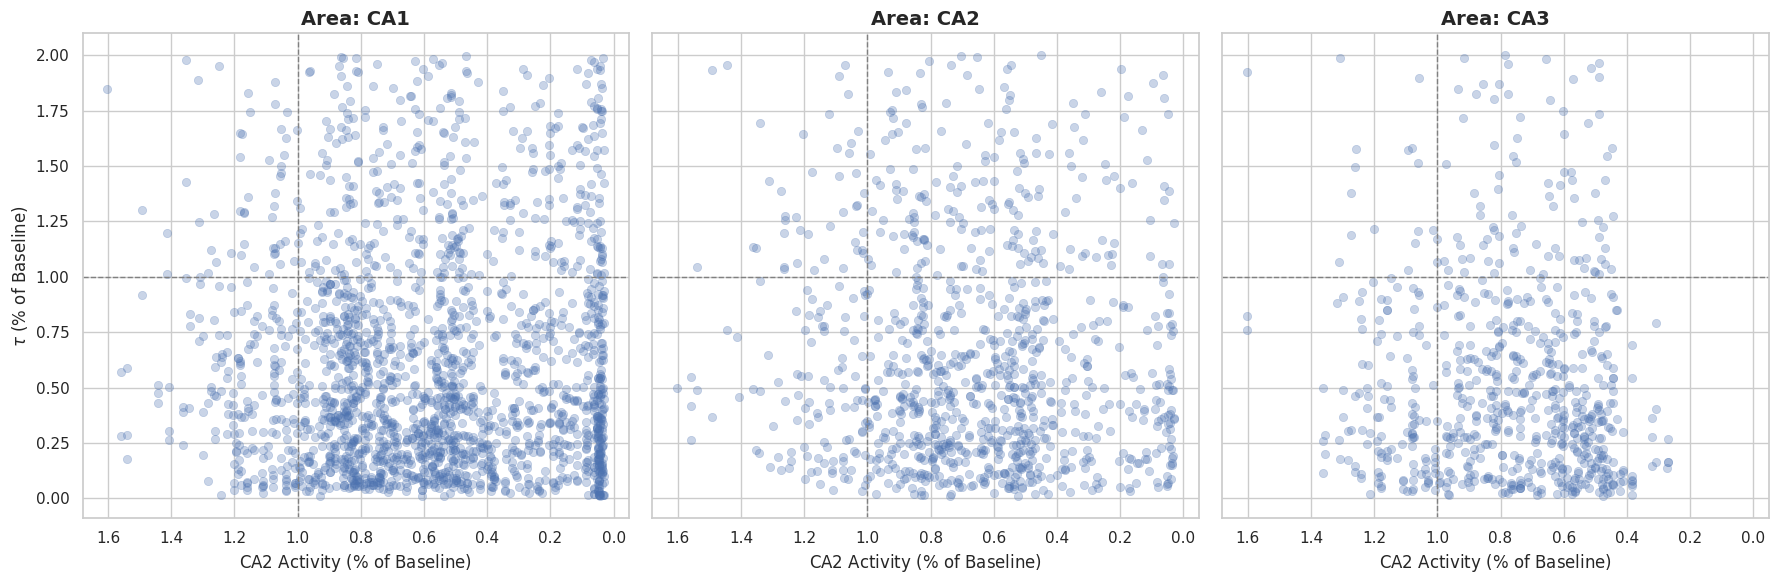

In [10]:
%matplotlib inline

upper_tau_change = 2

###

# Ensure we are only plotting rows where we actually have both percentages
plot_df = final_df.dropna(subset=['tau_percentage', 'ca2_activity_percentage'])
plot_df = plot_df[plot_df['tau_percentage'] < upper_tau_change]


# Set the visual style
sns.set_theme(style="whitegrid")

# Create a figure with 3 subplots (1 for each Area)
fig, axes = plt.subplots(1, 3, figsize=(18, 6), sharey=True, sharex=True)
areas = ['CA1', 'CA2', 'CA3']

for i, area in enumerate(areas):
    # Filter data for the specific area
    subset = plot_df[plot_df['Area'] == area]
    
    # Create the scatter plot
    sns.scatterplot(
        data=subset,
        x='ca2_activity_percentage',
        y='tau_percentage',
        ax=axes[i],
        alpha=0.3,
        edgecolor=None
    )
    
    # Add a reference line at 1.0 (100%) for both axes
    axes[i].axvline(1, color='gray', linestyle='--', linewidth=1)
    axes[i].axhline(1, color='gray', linestyle='--', linewidth=1)
    
    # Titles and Labels
    axes[i].set_title(f'Area: {area}', fontsize=14, fontweight='bold')
    axes[i].set_xlabel('CA2 Activity ($\%$ of Baseline)', fontsize=12)
    
    # Only label the first y-axis since they share it
    if i == 0:
        axes[i].set_ylabel(r'$\tau$ ($\%$ of Baseline)', fontsize=12)


for ax in axes: ax.invert_xaxis()

plt.tight_layout()